#### Temporal pattern analysis

Looking at the patterns in both series before modelling. Only the train part is used.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# seaborn = nicer charts (used for the heatmap)
import seaborn as sns
# periodogram finds the repeating cycles, MSTL splits the series into trend + seasonal parts,
# acf/pacf measure how much the load depends on earlier hours, adfuller/kpss test if the series is stationary
from scipy.signal import periodogram
from statsmodels.tsa.seasonal import MSTL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, adfuller, kpss
import warnings
warnings.filterwarnings("ignore")

os.makedirs("../figures", exist_ok=True)

In [2]:
# why: only the train part is read, so nothing about the test period is seen before the models are built
pjm = pd.read_parquet("../data/processed/pjme_train.parquet")
# read_parquet() loads the files saved in notebook 02
uci = pd.read_parquet("../data/processed/uci_train.parquet")
print(pjm.shape, uci.shape)

(101774, 11) (24212, 11)


##### Daily, weekly and yearly profiles

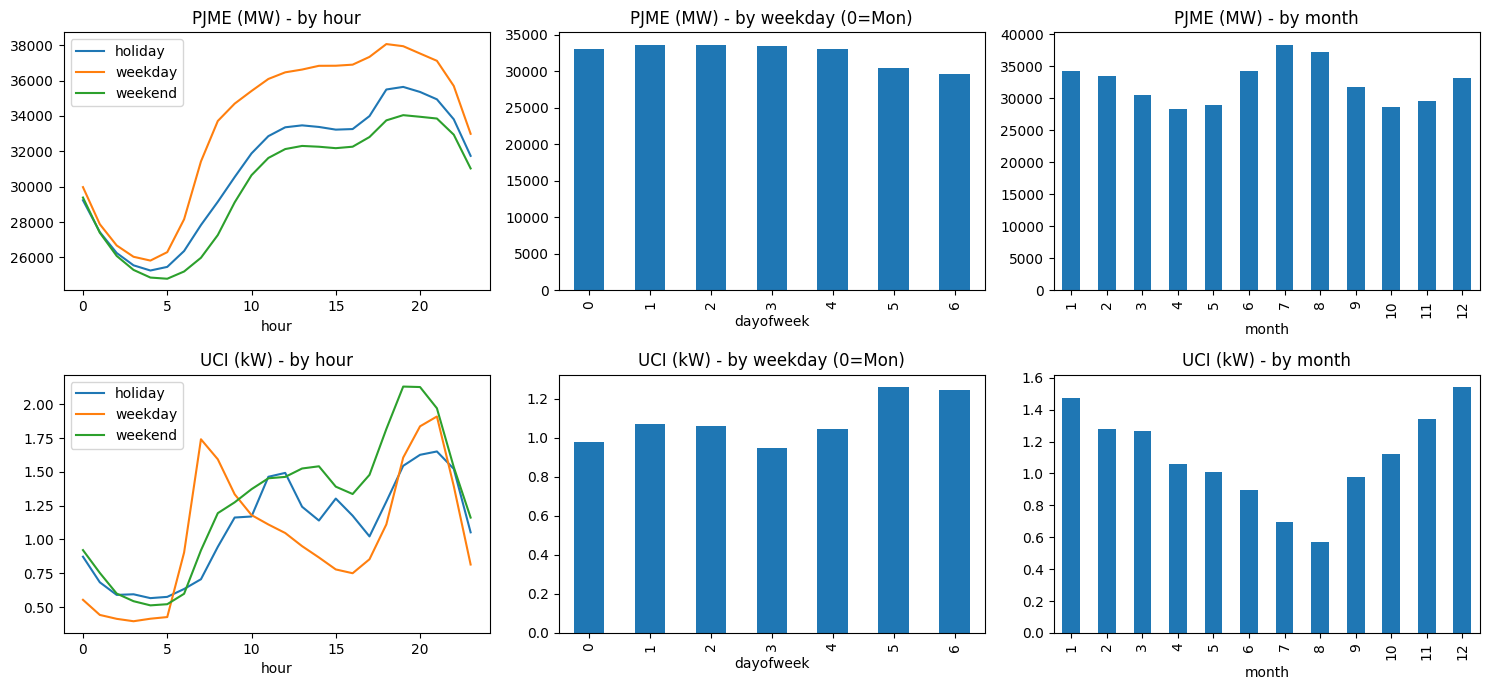

In [3]:
# why: these charts answer when demand is high and low (hour, weekday, month).
# this is the first part of the temporal pattern analysis in the project
fig, ax = plt.subplots(2, 3, figsize=(15, 7))

for i, (df, name) in enumerate([(pjm, "PJME (MW)"), (uci, "UCI (kW)")]):
    # np.where(condition, a, b) = a if the condition is true, else b.
    # here every hour gets a label: holiday, weekend or weekday
    day_type = np.where(df["holiday"] == 1, "holiday", np.where(df["weekend"] == 1, "weekend", "weekday"))
    # average load for each hour and day type. unstack() makes one column (one line in the chart) per day type
    df.groupby([df["hour"], day_type])["load"].mean().unstack().plot(ax=ax[i, 0])
    ax[i, 0].set_title(name + " - by hour")

    # average load for each day of the week, as bars
    df.groupby("dayofweek")["load"].mean().plot(kind="bar", ax=ax[i, 1])
    ax[i, 1].set_title(name + " - by weekday (0=Mon)")

    df.groupby("month")["load"].mean().plot(kind="bar", ax=ax[i, 2])
    ax[i, 2].set_title(name + " - by month")

plt.tight_layout()
plt.savefig("../figures/03_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

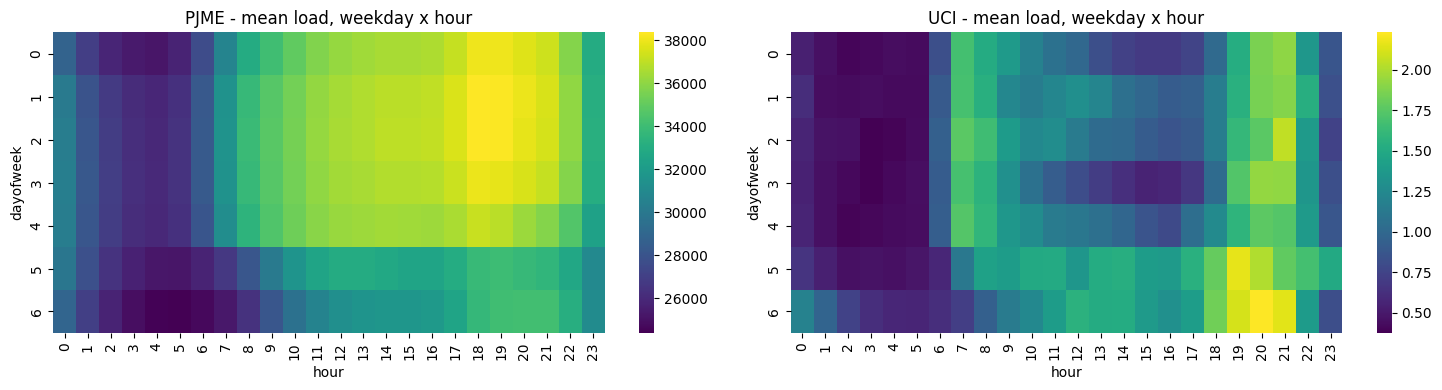

In [4]:
# why: the heatmap shows the daily and the weekly pattern together in one picture
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, df, name in [(ax[0], pjm, "PJME"), (ax[1], uci, "UCI")]:
    # pivot_table makes a grid: rows = day of week, columns = hour, value = average load
    sns.heatmap(df.pivot_table(index="dayofweek", columns="hour", values="load"), ax=a, cmap="viridis")
    a.set_title(name + " - mean load, weekday x hour")
plt.tight_layout()
plt.savefig("../figures/03_heatmap_weekday_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# peak hour by season
for df, name in [(pjm, "PJME"), (uci, "UCI")]:
    # map() changes the month number into a season name, e.g. 7 -> summer
    season = df["month"].map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                              6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
    # average load for each (season, hour), then idxmax() gives the hour with the highest load in each season
    print(name, df.groupby([season, "hour"])["load"].mean().groupby(level=0).idxmax().str[1].to_dict())

PJME {'autumn': 20, 'spring': 21, 'summer': 17, 'winter': 19}
UCI {'autumn': 20, 'spring': 21, 'summer': 21, 'winter': 20}


Notes:
- PJME: highest load in Jul/Aug (cooling) and a second smaller peak in Dec-Feb (heating). Lowest in Apr/May and Oct.
- PJME weekdays clearly higher than weekends, holidays look like weekends.
- PJME daily peak moves with the season - around 17h in summer, 19-21h the rest of the year.
- UCI is the other way round: highest in winter, lowest in Jul/Aug (probably holidays away from home).
- UCI weekends are higher than weekdays (people at home), evening peak around 20-21h.

##### STL decomposition (daily + weekly)

In [6]:
# why: MSTL splits the load into trend + daily pattern + weekly pattern + rest.
# it shows how strong the daily and weekly cycles are, which tells us how easy the series is to predict
pjm_mstl = MSTL(pjm["load"], periods=(24, 168)).fit()
# periods=(24, 168): 24 hours = one day, 168 hours = one week. fit() runs the decomposition
uci_mstl = MSTL(uci["load"], periods=(24, 168)).fit()

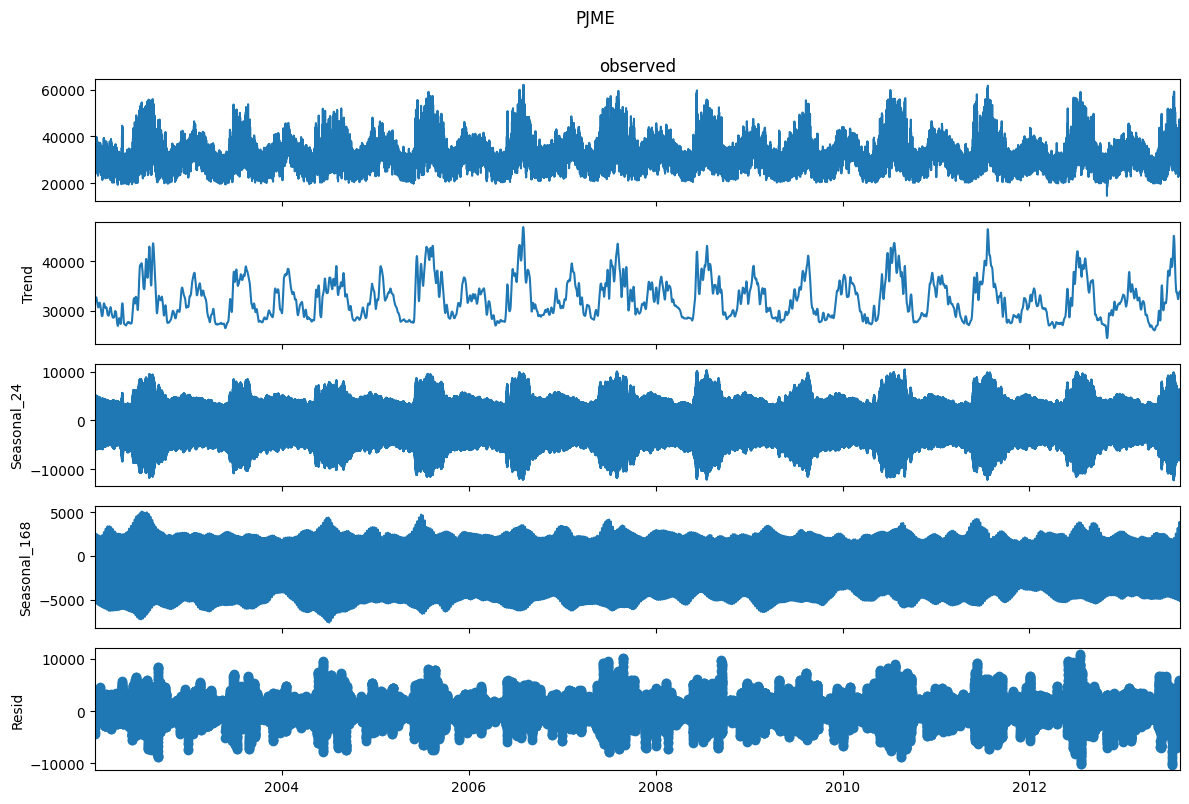

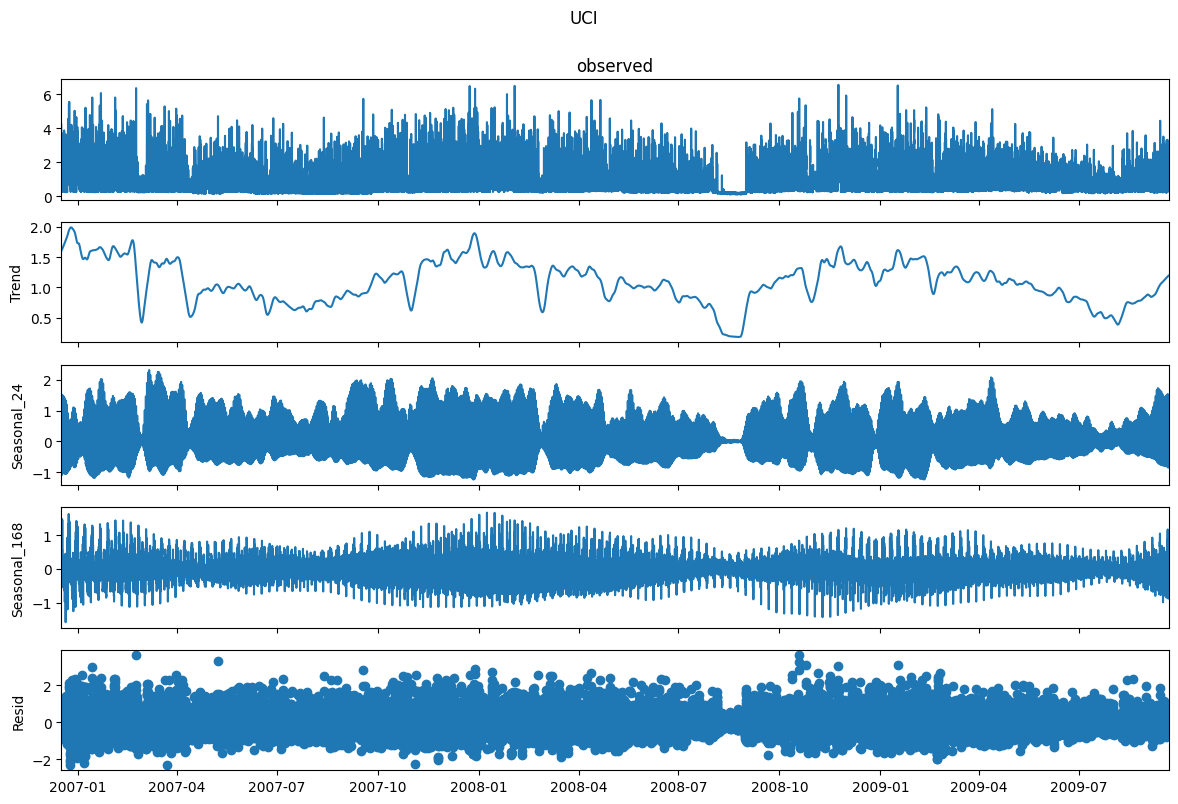

In [7]:
for res, name in [(pjm_mstl, "PJME"), (uci_mstl, "UCI")]:
    # res.plot() draws all the parts (observed, trend, seasonal 24, seasonal 168, residual)
    fig = res.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(name, y=1.0)
    plt.tight_layout()
    plt.savefig(f"../figures/03_mstl_{name.lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

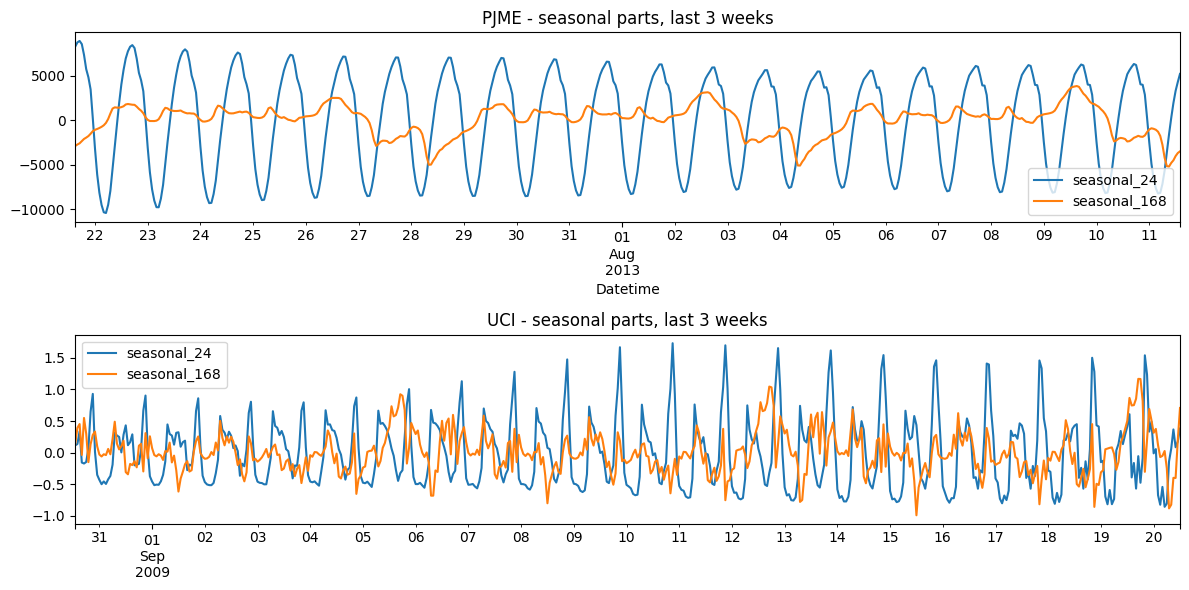

In [8]:
# zoom on 3 weeks so the daily / weekly parts can be seen
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
for a, res, name in [(ax[0], pjm_mstl, "PJME"), (ax[1], uci_mstl, "UCI")]:
    # iloc[-24 * 21:] = the last 504 hours = 3 weeks
    part = res.seasonal.iloc[-24 * 21:]
    part.plot(ax=a)
    a.set_title(name + " - seasonal parts, last 3 weeks")
plt.tight_layout()
plt.savefig("../figures/03_seasonal_3_weeks.png", dpi=150, bbox_inches="tight")
plt.show()

Strength of trend / seasonality (Hyndman & Athanasopoulos): 1 - var(resid) / var(component + resid).
Close to 1 = strong, close to 0 = weak.

In [9]:
# strength: how strong one part (trend or seasonal) is, from 0 (weak) to 1 (strong).
# if the rest (resid) is small compared to the part, the result is close to 1.
# e.g. PJME daily = 0.87 (strong), UCI daily = 0.53 (weaker)
def strength(comp, resid):
    # max(0, ...) so the value never goes below 0
    return max(0, 1 - resid.var() / (comp + resid).var())

rows = []
for res, name in [(pjm_mstl, "PJME"), (uci_mstl, "UCI")]:
    rows.append([name,
                 strength(res.trend, res.resid),
                 strength(res.seasonal["seasonal_24"], res.resid),
                 strength(res.seasonal["seasonal_168"], res.resid)])
# one table with the three strengths for both datasets
strengths = pd.DataFrame(rows, columns=["dataset", "trend", "daily", "weekly"]).set_index("dataset")
strengths.round(3)

,trend,daily,weekly
dataset,,,
PJME,0.852,0.867,0.554
UCI,0.306,0.532,0.296


PJME has strong daily seasonality and a clear weekly one. For UCI everything is much weaker, the residual is large (noisy household behaviour).

##### Autocorrelation

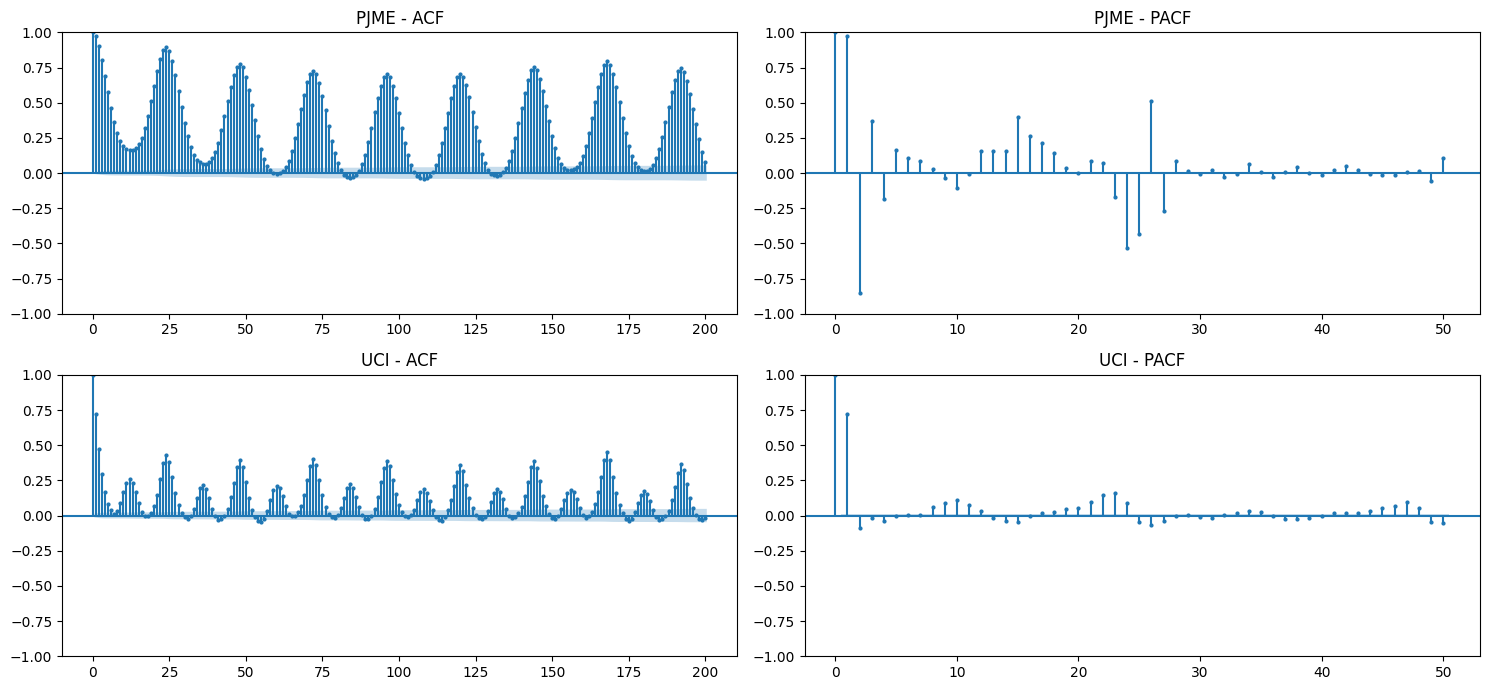

In [10]:
# why: autocorrelation shows how much the load now is linked to the load some hours before.
# high values at lag 24 and 168 mean the same hour yesterday / last week is useful, so these are used as lag features
fig, ax = plt.subplots(2, 2, figsize=(15, 7))
for i, (df, name) in enumerate([(pjm, "PJME"), (uci, "UCI")]):
    # plot_acf draws the autocorrelation for lags 1 to 200 hours
    plot_acf(df["load"], lags=200, ax=ax[i, 0], markersize=2)
    ax[i, 0].set_title(name + " - ACF")
    # plot_pacf = the direct link with each lag, after removing the effect of the lags in between
    plot_pacf(df["load"], lags=50, ax=ax[i, 1], markersize=2, method="ywm")
    ax[i, 1].set_title(name + " - PACF")
plt.tight_layout()
plt.savefig("../figures/03_acf_pacf.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
lags = [1, 2, 12, 24, 48, 168]
# acf() gives the values as numbers. [lags] picks only the lags we want for the table
acf_table = pd.DataFrame({
    "PJME": acf(pjm["load"], nlags=168)[lags],
    "UCI": acf(uci["load"], nlags=168)[lags],
}, index=lags)
acf_table.index.name = "lag"
acf_table.round(3)

,PJME,UCI
lag,,
1,0.974,0.720
2,0.904,0.475
12,0.165,0.258
24,0.894,0.432
48,0.777,0.396
168,0.795,0.451


PJME: very high autocorrelation at lag 1, 24 and 168, so the lag_24 / lag_168 features make sense.
UCI: lag 1 is only ~0.7 and the daily/weekly lags are ~0.43-0.45, so it will be much harder to predict, especially 24h and 168h ahead.

##### Periodogram

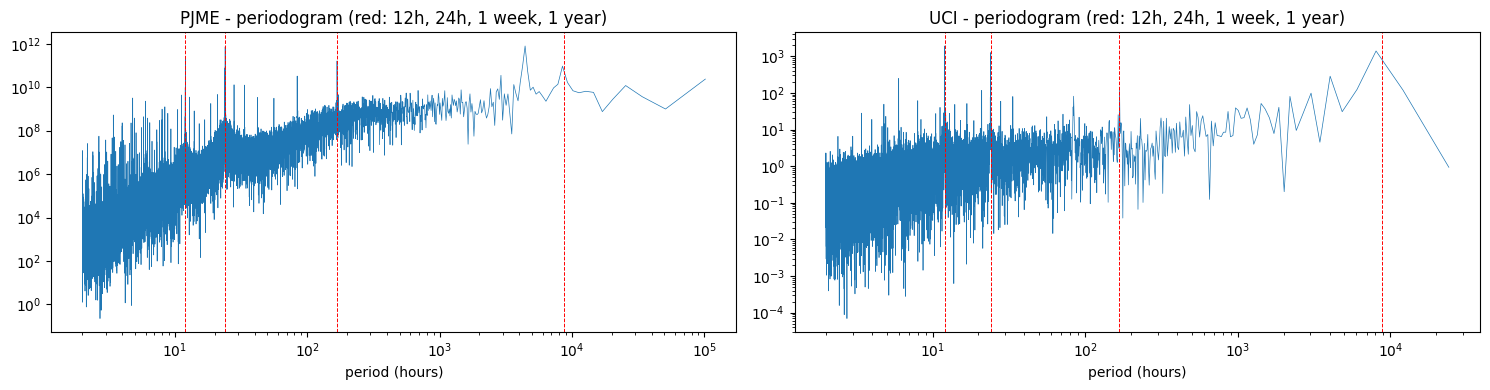

In [12]:
# why: the periodogram is another way to find the cycles. a high point at 24 means a strong daily cycle
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, df, name in [(ax[0], pjm, "PJME"), (ax[1], uci, "UCI")]:
    # the mean is taken away first so the constant level does not hide the cycles. fs=1 = one sample per hour
    f, p = periodogram(df["load"] - df["load"].mean(), fs=1)
    # f is the frequency, so 1 / f is the length of the cycle in hours. loglog = both axes on a log scale
    a.loglog(1 / f[1:], p[1:], lw=0.5)
    for h in [12, 24, 168, 8766]:
        # red dashed lines at 12h, 24h, 1 week and 1 year
        a.axvline(h, color="red", ls="--", lw=0.7)
    a.set_xlabel("period (hours)")
    a.set_title(name + " - periodogram (red: 12h, 24h, 1 week, 1 year)")
plt.tight_layout()
plt.savefig("../figures/03_periodogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# strongest periods
for df, name in [(pjm, "PJME"), (uci, "UCI")]:
    f, p = periodogram(df["load"] - df["load"].mean(), fs=1)
    # sort the cycles by power and keep the 6 strongest
    top = pd.Series(p[1:], index=(1 / f[1:]).round(1)).sort_values(ascending=False).head(6)
    print(name, list(top.index))

PJME [4425.0, 24.0, 24.0, 12.0, 167.9, 24.1]
UCI [12.0, 8070.7, 24.0, 12.0, 4035.3, 6.0]


PJME: the main cycles are 24h and ~4400h (half a year - summer and winter peaks), then 12h and weekly.
UCI: 12h and 24h (morning and evening peaks), plus the yearly cycle.

##### Stationarity

ADF: H0 = unit root (not stationary). KPSS: H0 = stationary. Using daily means to keep it quick.

In [14]:
# why: stationary = the mean and the spread do not change over time.
# it is checked so we know if the series has a trend the models must deal with
rows = []
for df, name in [(pjm, "PJME"), (uci, "UCI")]:
    # daily means are used to keep the tests quick. dropna() removes empty days
    daily = df["load"].resample("D").mean().dropna()
    # [1] takes the p-value. ADF: small p (< 0.05) = stationary
    adf_p = adfuller(daily, autolag="AIC")[1]
    # KPSS is the other way round: small p (< 0.05) = NOT stationary
    kpss_p = kpss(daily, regression="c", nlags="auto")[1]
    rows.append([name, adf_p, kpss_p])
stat = pd.DataFrame(rows, columns=["dataset", "adf_p", "kpss_p"]).set_index("dataset")
stat.round(4)

,adf_p,kpss_p
dataset,,
PJME,0.0000,0.1000
UCI,0.0251,0.0626


(KPSS p-values are capped at 0.1 by statsmodels.)
PJME: ADF rejects unit root and KPSS doesn't reject stationarity -> stationary around a constant level.
UCI: ADF rejects at 5% (p ~0.03) and KPSS just doesn't reject (p ~0.06), so stationary but borderline - the yearly cycle is strong compared to the short series (less than 3 years in train).

##### Peak and low demand periods

Peak = top 10% of hours, low = bottom 10%.

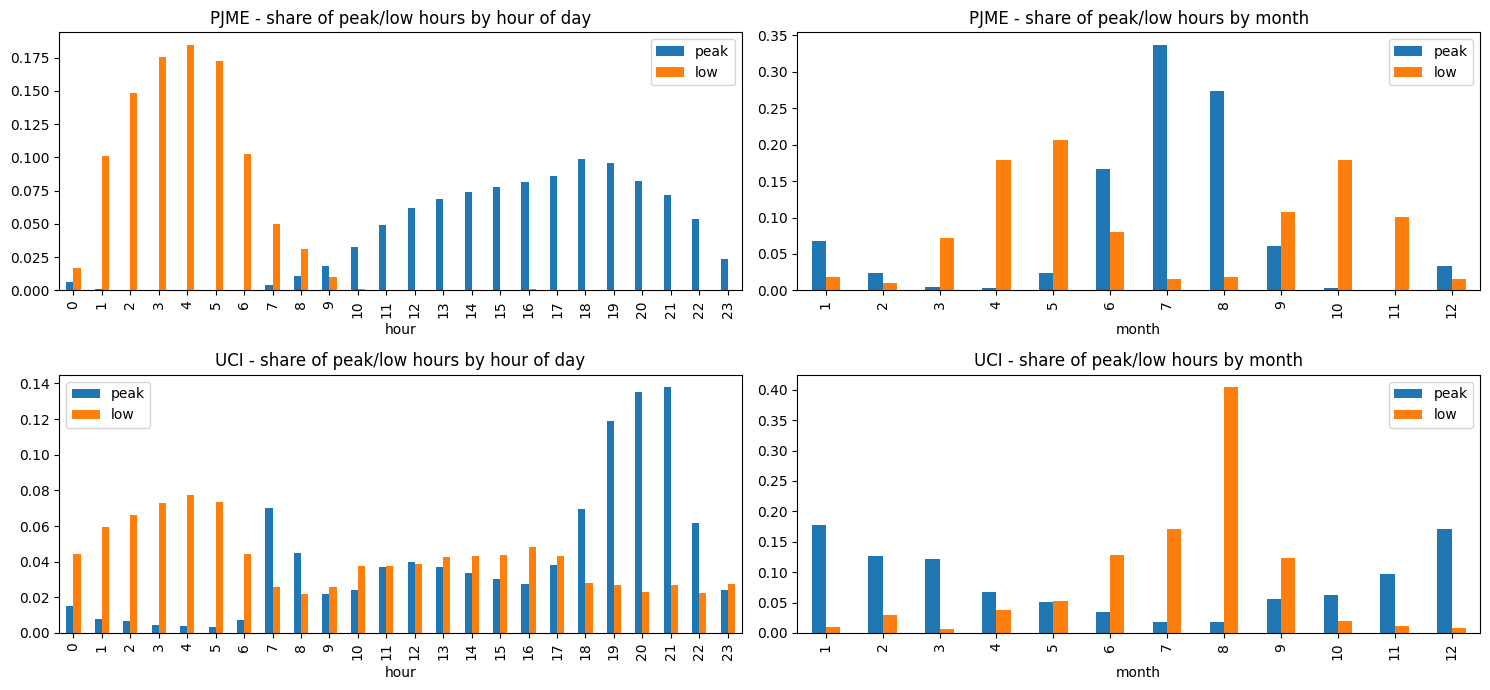

{'PJME': (24389.0, 40850.7), 'UCI': (0.2609, 2.3881833333333335)}

In [15]:
# why: peak hours matter most for the grid. the errors of the models are reported for peak and low hours
# in notebook 06, so here we look at when these hours happen
fig, ax = plt.subplots(2, 2, figsize=(15, 7))
thresholds = {}
for i, (df, name) in enumerate([(pjm, "PJME"), (uci, "UCI")]):
    # quantile(0.9) = the value that 90% of the hours are below. hours above it are the top 10% (peak)
    hi = df["load"].quantile(0.9)
    lo = df["load"].quantile(0.1)
    thresholds[name] = (lo, hi)
    peak = df[df["load"] >= hi]
    low = df[df["load"] <= lo]

    # value_counts(normalize=True) = share of the peak hours in each hour of the day, e.g. 0.15 = 15%
    pd.DataFrame({"peak": peak["hour"].value_counts(normalize=True),
                  "low": low["hour"].value_counts(normalize=True)}).sort_index().fillna(0).plot(kind="bar", ax=ax[i, 0])
    ax[i, 0].set_title(name + " - share of peak/low hours by hour of day")

    pd.DataFrame({"peak": peak["month"].value_counts(normalize=True),
                  "low": low["month"].value_counts(normalize=True)}).sort_index().fillna(0).plot(kind="bar", ax=ax[i, 1])
    ax[i, 1].set_title(name + " - share of peak/low hours by month")
plt.tight_layout()
plt.savefig("../figures/03_peak_low_hours.png", dpi=150, bbox_inches="tight")
plt.show()

thresholds

PJME peak hours are mostly summer afternoons/evenings, low hours are spring/autumn nights.
UCI peaks are winter evenings. These periods will be used to break down the model errors later.

##### PJME vs UCI

In [16]:
# why: one table that compares the two datasets, used later to explain why the household is harder to predict
rows = []
for df, name in [(pjm, "PJME"), (uci, "UCI")]:
    s = df["load"]
    rows.append({
        "dataset": name,
        "mean": s.mean(),
        # cv = std / mean. it shows how variable the load is, and can be compared between MW and kW
        "cv": s.std() / s.mean(),
        "peak_to_mean": s.max() / s.mean(),
        # diff() = change from one hour to the next. this is the average size of that change, divided by the mean
        "hourly_change_cv": s.diff().abs().mean() / s.mean(),
        "acf_24": acf(s, nlags=24)[24],
        "acf_168": acf(s, nlags=168)[168],
        "daily_strength": strengths.loc[name, "daily"],
        "weekly_strength": strengths.loc[name, "weekly"],
    })
summary = pd.DataFrame(rows).set_index("dataset")
summary.round(3)

,mean,cv,peak_to_mean,hourly_change_cv,acf_24,acf_168,daily_strength,weekly_strength
dataset,,,,,,,,
PJME,32410.489,0.200,1.913,0.035,0.894,0.795,0.867,0.554
UCI,1.087,0.853,6.036,0.409,0.432,0.451,0.532,0.296


UCI is about 4x more variable (cv 0.85 vs 0.20) and changes ~12x more from hour to hour. Expect bigger errors for UCI and smaller gains from longer input windows.

In [17]:
# save the table so the dashboard and the report can use it
summary.to_csv("../data/processed/pattern_summary.csv")